# 03 · Feature Engineering (leakage-safe)

**Goal:** turn the daily revenue series into model inputs, and *prove* with executable checks that no feature uses information from the prediction day or later.

> Scope guard: only the **pool** (before 2011-11-09) is used. All feature code lives in `src/feature_engineering.py` and is the single source of truth for training, testing and the Streamlit app.

## The golden rule

For a prediction date *t*, every feature may use only things known **before** *t*:

* calendar facts about *t* itself (weekday, month, holiday) are fine because they are known in advance;
* past revenue is fine **only if it is strictly older than *t*** (lags with k >= 1; rolling windows that end at *t* - 1);
* nothing is *fitted* on data here (no scaling or imputation), so nothing can leak through preprocessing. The one model that needs scaling (Linear Regression) has its scaler inside a pipeline that is fitted on training rows only.

## Feature catalogue

| Feature | What it is | How it is computed | Why it may help | Leakage safeguard |
|---|---|---|---|---|
| `day_of_week` | 0 = Monday ... 6 = Sunday | from the date | strong weekly rhythm; Saturday is closed | calendar fact |
| `day_of_month`, `month`, `quarter`, `week_of_year`, `day_of_year` | position in the year | from the date | yearly seasonality (autumn ramp) | calendar fact |
| `is_weekend` | 1 on Saturday/Sunday | from the date | weekend trading differs | calendar fact |
| `is_uk_holiday` | Good Friday, Easter Sun/Mon, early-May, spring and summer bank holidays, 2011-04-29 | fixed holiday rules | business closed (revenue 0) | rules known years ahead |
| `is_year_end_closure` | 24 Dec - 3 Jan | from the date | business closed in both observed years | rule fixed from the pool |
| `lag_1`, `lag_7`, `lag_14`, `lag_28` | revenue k days earlier | `series.shift(k)` | yesterday + same weekday 1, 2, 4 weeks ago | k >= 1 so only the past |
| `rolling_mean_7`, `_14`, `_28` | average revenue of the previous w days | `series.shift(1).rolling(w).mean()` | current seasonal level | window ends at t - 1, excludes t |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":          # works from the project root or from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from src import config, plotting
from src import data_preprocessing as dp, evaluate as ev, feature_engineering as fe, forecast as fc
plotting.apply_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
GBP = FuncFormatter(plotting.gbp)
print("project folder:", ROOT.name)

project folder: retail-sales-forecasting


In [2]:
series = dp.load_revenue_series()
pool, test = ev.chronological_split(series)            # test is NOT used in this notebook
X = fe.build_features(pool)
print(f"Pool: {pool.index[0].date()} -> {pool.index[-1].date()} ({len(pool)} days)")
print("Feature columns:", list(X.columns))
X.iloc[[0, 28, 29, -1]].T

Pool: 2009-12-01 -> 2011-11-08 (708 days)
Feature columns: ['day_of_week', 'day_of_month', 'month', 'quarter', 'week_of_year', 'day_of_year', 'is_weekend', 'is_uk_holiday', 'is_year_end_closure', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_mean_14', 'rolling_mean_28']


date,2009-12-01,2009-12-29,2009-12-30,2011-11-08
day_of_week,1.00,1.00,2.00,1.00
day_of_month,1.00,29.00,30.00,8.00
month,12.00,12.00,12.00,11.00
quarter,4.00,4.00,4.00,4.00
week_of_year,49.00,53.00,53.00,45.00
day_of_year,335.00,363.00,364.00,312.00
is_weekend,0.00,0.00,0.00,0.00
is_uk_holiday,0.00,0.00,0.00,0.00
is_year_end_closure,0.00,1.00,1.00,0.00
lag_1,NaN,0.00,0.00,"84,326.52"


The first rows are mostly incomplete: `lag_28` and `rolling_mean_28` need 28 earlier days, so the first 28 days of the series cannot be used for training. Rows with any missing feature are dropped by `make_training_set`; nothing is imputed.

## 1 · Is the holiday / closure knowledge consistent with the pool data?

In [3]:
cal = fe.calendar_features(pool.index)
flag = fe.known_closure_mask(pool.index)
zero_not_saturday = (pool == 0) & (cal["day_of_week"] != 5)

print("Zero-revenue days that are not Saturdays:", int(zero_not_saturday.sum()))
print("   ...explained by the holiday / year-end flags:", int((zero_not_saturday & flag).sum()))
print("   ...unexplained:", list(pool.index[zero_not_saturday & ~flag].strftime("%Y-%m-%d")))
print("Flagged closure days that had revenue:", int((flag & (pool > 0)).sum()))
sat = cal["day_of_week"] == 5
print(f"Saturdays: {int(sat.sum())} in the pool, {int((sat & (pool > 0)).sum())} with any revenue")

Zero-revenue days that are not Saturdays: 31
   ...explained by the holiday / year-end flags: 31
   ...unexplained: []
Flagged closure days that had revenue: 0
Saturdays: 101 in the pool, 1 with any revenue


**Result.** Every non-Saturday zero-revenue day in the pool is explained by the holiday or year-end flags, and no flagged day had any revenue. That is why these two calendar rules are used both as features **and** as a deterministic "closed = 0 forecast" rule. Saturdays are *not* hard-coded because one Saturday did trade; the model handles them.

## 2 · Executable leakage checks

In [4]:
rng = np.random.default_rng(config.RANDOM_SEED)
usable = pool.index[config.MAX_LOOKBACK:]
dates = usable[rng.choice(len(usable), size=25, replace=False)]

# (a) every lag equals the value exactly k days earlier
lags_ok = all(X.loc[d, f"lag_{k}"] == pool.loc[d - pd.Timedelta(days=k)] for d in dates for k in config.LAG_PERIODS)

# (b) every rolling mean equals the mean of the PREVIOUS w days (and not the window that includes today)
roll_ok = all(np.isclose(X.loc[d, f"rolling_mean_{w}"],
                         pool.loc[d - pd.Timedelta(days=w): d - pd.Timedelta(days=1)].mean())
              for d in dates for w in config.ROLLING_WINDOWS)
# (b2) compare with the WRONG window that would include today. The two windows differ by
#      (today - value 7 days ago)/7, so the test is only meaningful on days where those values differ.
informative = [d for d in dates if pool.loc[d] != pool.loc[d - pd.Timedelta(days=7)]]
roll_not_today = len(informative) > 0 and all(
    not np.isclose(X.loc[d, "rolling_mean_7"], pool.loc[d - pd.Timedelta(days=6): d].mean()) for d in informative)

# (c) rewriting day t and everything after it must not change any feature of day t or earlier
t = pool.index[400]
rewritten = pool.copy()
rewritten.loc[t:] = rewritten.loc[t:] * 10 + 100_000
X_rewritten = fe.build_features(rewritten)
future_ok = np.allclose(X.loc[t].to_numpy(float), X_rewritten.loc[t].to_numpy(float)) and X.loc[:t].equals(X_rewritten.loc[:t])

# (d) cutting the series at day T must give the same features for all days up to T
T = pool.index[500]
truncation_ok = fe.build_features(pool.loc[:T]).equals(X.loc[:T])

# (e) the recursive forecaster builds the same feature row as the vectorised code
class Recorder:
    def __init__(self): self.rows = []
    def predict(self, frame): self.rows.append(frame.copy()); return np.array([0.0])
rec = Recorder()
origin = pool.index[600]
fc.recursive_forecast(rec, pool.loc[:origin], 1, apply_closures=False)
recursive_ok = np.allclose(rec.rows[0].iloc[0].to_numpy(float), X.loc[origin + pd.Timedelta(days=1)].to_numpy(float))

checks = {
    "lags use exactly the value k days earlier": lags_ok,
    "rolling means cover the previous w days": roll_ok,
    "rolling means do not include today's value": roll_not_today,
    "changing day t and later never changes features of day t or earlier": future_ok,
    "features up to T are identical when data after T is removed": truncation_ok,
    "recursive forecaster rows equal the vectorised features": recursive_ok,
}
for name, passed in checks.items():
    print(("PASS  " if passed else "FAIL  ") + name)
assert all(checks.values())

PASS  lags use exactly the value k days earlier
PASS  rolling means cover the previous w days
PASS  rolling means do not include today's value
PASS  changing day t and later never changes features of day t or earlier
PASS  features up to T are identical when data after T is removed
PASS  recursive forecaster rows equal the vectorised features


All checks pass. Check (c) is the strongest: we literally rewrite today and the entire future, and no feature for today (or any earlier day) moves. Check (e) shows that the multi-step forecaster and the training code build identical rows, so there is no train/serve mismatch.

## 3 · The training matrix

In [5]:
X_train, y_train = fe.make_training_set(pool)
print(f"Training rows: {len(X_train)} (first row {X_train.index[0].date()}, last row {X_train.index[-1].date()})")
print(f"Rows dropped for lack of history: {len(pool) - len(X_train)} (= the first {config.MAX_LOOKBACK} days)")
print("Missing values in the training matrix:", int(X_train.isna().sum().sum()))

Training rows: 680 (first row 2009-12-29, last row 2011-11-08)
Rows dropped for lack of history: 28 (= the first 28 days)
Missing values in the training matrix: 0


## 4 · How do the features relate to revenue? (pool only)

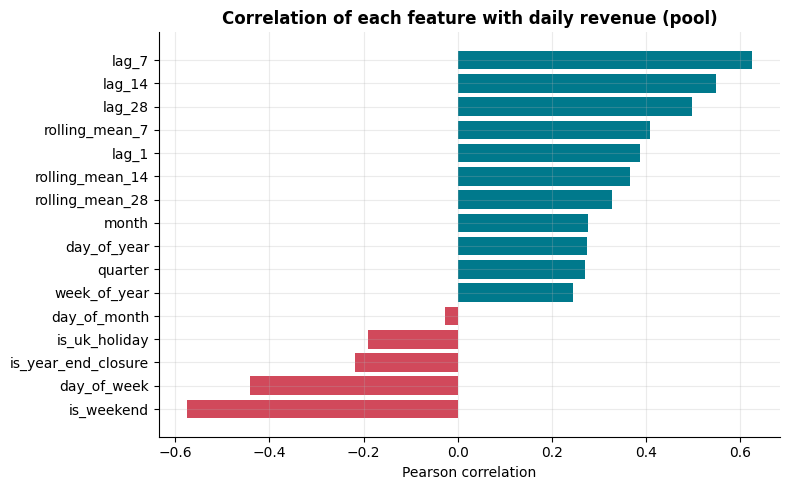

lag_7                  0.62
lag_14                 0.55
lag_28                 0.50
rolling_mean_7         0.41
lag_1                  0.39
rolling_mean_14        0.37
rolling_mean_28        0.33
month                  0.28
day_of_year            0.27
quarter                0.27
week_of_year           0.24
day_of_month          -0.03
is_uk_holiday         -0.19
is_year_end_closure   -0.22
day_of_week           -0.44
is_weekend            -0.57


In [6]:
corr = X_train.corrwith(y_train).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(corr.index, corr.values, color=[plotting.COLORS["accent"] if v >= 0 else plotting.COLORS["forecast"] for v in corr.values])
ax.set_title("Correlation of each feature with daily revenue (pool)")
ax.set_xlabel("Pearson correlation")
fig.tight_layout()
plotting.save_figure(fig, "fig13_feature_correlations.png")
plt.show()
print(corr.round(3).sort_values(ascending=False).to_string())

**How to read this.** Correlation shows a *linear association* in the pool, nothing more. It does not mean any feature *causes* revenue, and models (especially trees) can use features in non-linear ways that this chart cannot show.

The closure flags and `is_weekend` associate negatively with revenue (closed days have none), while the recent-level features (`rolling_mean_*`) and the weekly lags are positively associated. `day_of_year`, `month`, `week_of_year` and `quarter` describe the same yearly position in four ways; they overlap heavily, which is harmless for tree models but is the reason the linear model uses one-hot weekday and month instead.